# Transient Kerr Effect of a Magnetization Gradient

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/dschick/udkm1Dsim/blob/develop/examples/06-optics/03-transient_kerr_effect.ipynb)

In this example the time-resolved longitudinal Kerr rotation and ellipticity of a 40 nm thick Ni film after optical excitation are calculated for diffusive and ballistic transport, inspired by {cite:t}`ashok2025`.
For diffusive transport, the gradient of the optical excitation results in a magnetization gradient, which persists for a few picoseconds, while ballistic transport distributes the energy almost instantaneously, so that the magnetization stays almost homogeneous, see Fig. 1 of the paper.
Both cases are calculated by the microscopic three-temperature model (M3TM) of {cite:t}`koopmans2010`, see the [M3TM example](#example_m3tm), instead of the $\mu T$ model of the paper.
The exact eigenmodes of {py:class}`BerremanStepanov <udkm1Dsim.simulations.scattering.berreman.BerremanStepanov>` take into account the full depth dependence of the magnetization, see the [scattering overview](#example_scattering_overview).
The angle of incidence and the polarization of the probe are scanned to find the conditions, for which the complex Kerr effect of visible light distinguishes both cases best.

:::{admonition} Reference {cite}`ashok2025`
:class: seealso
S. Ashok, J. Hoefer, M. Stiehl, M. Aeschlimann, H. C. Schneider, B. Rethfeld, and B. Stadtmüller, *Signatures of ballistic and diffusive transport in the time-dependent Kerr-response of magnetic materials*, [New J. Phys. 27, 063001 (2025)](https://doi.org/10.1088/1367-2630/adce23)
:::

:::{note}
All material parameters of this example are **estimated** or **made up**, so that the results are only qualitative.
:::

## Setup

Do all necessary imports and settings.

In [1]:
import matplotlib.pyplot as plt
import numpy as np

try:
    import udkm1Dsim as ud
except ImportError:
    %pip install udkm1Dsim
    import udkm1Dsim as ud

u = ud.u  # import the pint unit registry from udkm1Dsim
u.setup_matplotlib()  # use matplotlib with pint units

%matplotlib inline

## Structure

Refer to the [structure example](#example_structure) for more details.

The Ni film is built of 40 layers of 1 nm on an MgO substrate, so that the magnetization can vary with depth.
The refractive index of Ni at the pump wavelength of 800 nm and the probe wavelength of 400 nm is taken from the data of {cite:t}`johnson1974` in the [refractiveindex.info](https://refractiveindex.info) database, see the [example of the dielectric tensor](#example_dielectric).
Its magneto-optical response is given by the Voigt constant $Q$, which is **estimated** as a constant.
Its phase determines the depth sensitivity of the Kerr ellipticity and is chosen such that the results resemble the ones of {cite:t}`ashok2025`.

The parameters of the M3TM for Ni are **estimated** after {cite:t}`koopmans2010`, i.e. the electronic heat capacity $\gamma_e T_e$, the electron-phonon coupling $g$, the demagnetization rate $R$, and the Curie temperature $T_C$.
As in the [M3TM example](#example_m3tm), the magnetization is the 3rd sub-system.
The thermal conductivity of the electrons $\kappa_e T_e / T_p$ distinguishes both cases.
For diffusive transport, $\kappa_e$ = 80 W/(m K) is close to the one of Ni.
Ballistic transport is mimicked by a **made-up** $\kappa_e$ = 10000 W/(m K), so that the hot electrons distribute their energy across the film before they couple to the phonons and the spins.

In [2]:
Q = 0.009 + 0.0055j  # estimated Voigt constant of Ni at 400 nm
dielectric_Ni = ud.Dielectric(
    eps0=ud.Dispersion.from_refractiveindex("main", "Ni", "Johnson"),
    eps_mag=ud.Dispersion.from_array(None, Q, kind="voigt"),
)

rho = 8900  # density (kg/m³)
gamma_e = 1065 / rho  # electronic heat capacity (J/kg/K²)
g = 8e17  # electron-phonon coupling (W/m³/K)
R = 17.2e12  # demagnetization rate (1/s)
Tc = 627  # Curie temperature (K)
kappa_e = {"diffusive": 80, "ballistic": 10000}  # electronic thermal conductivity (W/m/K)

layers_Ni = {}
for name, kappa in kappa_e.items():
    layers_Ni[name] = ud.Layer(
        "Ni",
        "Ni",
        structural=ud.StructuralParameters(thickness=1 * u.nm, density=rho * u.kg / u.m**3),
        thermal=ud.ThermalParameters(
            heat_capacity=[f"{gamma_e}*T", 444 * u.J / u.kg / u.K, 1 / rho],
            therm_cond=[f"{kappa}*T_0/T_1", 10 * u.W / (u.m * u.K), 0],
            sub_system_coupling=[
                f"-{g}*(T_0-T_1)",
                f"{g}*(T_0-T_1)",
                f"{R}*T_2*T_1/{Tc}*(1-T_2*(1+2/(exp(2*T_2*{Tc}/T_0)-1)))",
            ],
            sub_system_labels=["e", "p", "m"],  # electrons, phonons, and magnetization
        ),
        optical=ud.OpticalParameters(dielectric=dielectric_Ni),
        magnetic=ud.MagneticParameters(magnetization=(0, 1, 0)),
    )
layer_Ni = layers_Ni["diffusive"]
print(
    f"optical penetration depth at 800 nm: {layer_Ni.get_opt_pen_depth(800 * u.nm).to('nm'):.1f~P}"
)
print(
    f"optical penetration depth at 400 nm: {layer_Ni.get_opt_pen_depth(400 * u.nm).to('nm'):.1f~P}"
)

optical penetration depth at 800 nm: 13.0 nm
optical penetration depth at 400 nm: 12.3 nm


The transparent MgO is described by a constant refractive index.
Its first 100 nm are part of the heat diffusion.

In [3]:
layer_MgO = ud.Layer(
    "MgO",
    "MgO",
    structural=ud.StructuralParameters(thickness=5 * u.nm, density=3580 * u.kg / u.m**3),
    thermal=ud.ThermalParameters(
        heat_capacity=[100 * u.J / u.kg / u.K, 877 * u.J / u.kg / u.K, 1],
        therm_cond=[0, 40 * u.W / (u.m * u.K), 0],
        sub_system_coupling=[0, 0, 0],
        sub_system_labels=["e", "p", "m"],
    ),
    optical=ud.OpticalParameters(
        dielectric=ud.Dielectric(eps0=ud.Dispersion.from_ref_index(1.75))
    ),
)

N = 40  # number of Ni layers
structures = {}
for name in kappa_e:
    structures[name] = ud.Structure(f"Ni on MgO, {name}")
    structures[name].add_sub_structure(layers_Ni[name], N)
    structures[name].add_sub_structure(layer_MgO, 20)
    structures[name].add_substrate(layer_MgO)
S = structures["diffusive"]
S

times,sub-structure,thickness
40,Ni,40 nm
20,MgO,100 nm


## Demagnetization

The pump pulse of 50 fs at 800 nm is absorbed by the Lambert-Beer law in the Ni film.
The absorbed fluence of 1 mJ/cm² is **estimated**, such that the surface is strongly but not completely demagnetized for diffusive transport, while {cite:t}`ashok2025` use 20 mJ/cm² in their $\mu T$ model.
The initial magnetization is the equilibrium $m = \tanh(m T_C / T)$ of the M3TM at 300 K.

In [4]:
delays = np.r_[-0.5:4:0.02] * u.ps
depth = np.r_[0.5:N] * u.nm  # center of the Ni layers

m_eq = 1
for _ in range(100):
    m_eq = np.tanh(m_eq * Tc / 300)

init_temp = np.zeros([S.num_layers, 3])
init_temp[:, :2] = 300
init_temp[:N, 2] = m_eq  # no magnetization of MgO

res_temps = {}
m = {}
for name in kappa_e:
    h = ud.Heat(structures[name], True, save_data=False, disp_messages=False, progress_bar=False)
    h.excitation = {
        "fluence": [1] * u.mJ / u.cm**2,
        "delay_pump": [0] * u.ps,
        "pulse_width": [0.05] * u.ps,
        "multilayer_absorption": False,
        "wavelength": 800 * u.nm,
    }
    h.heat_diffusion = True
    h.boundary_conditions = {"top_type": "isolator", "bottom_type": "isolator"}
    res_temps[name] = h.get_temp_map(delays, init_temp)
    m[name] = res_temps[name].temp_map[:, :, 2]

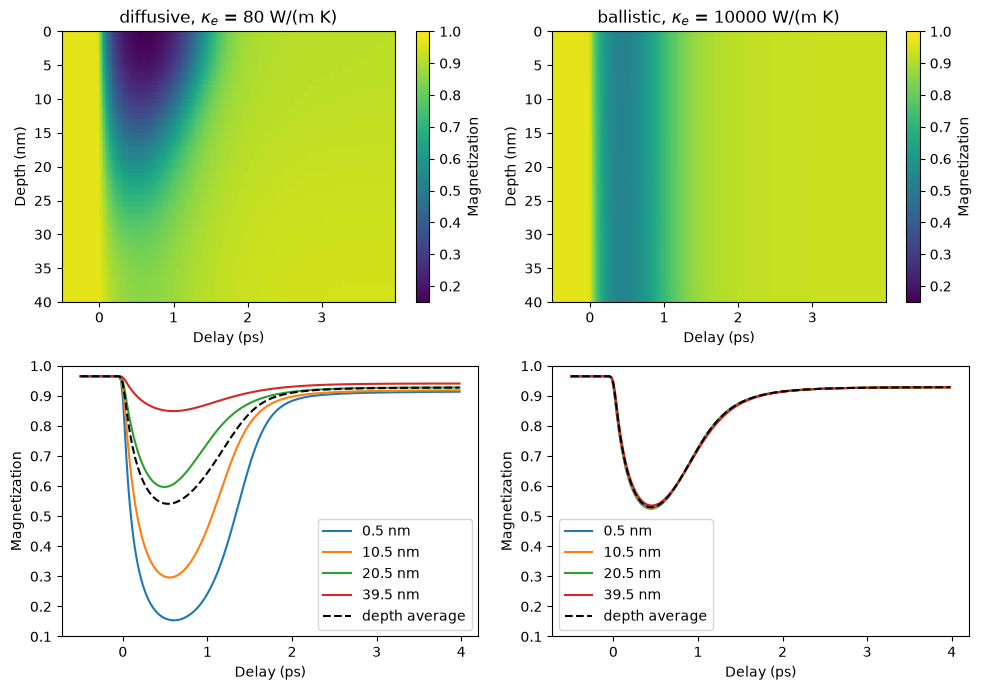

In [5]:
plt.figure(figsize=[10, 7])
for i, name in enumerate(m):
    plt.subplot(2, 2, i + 1)
    delays_ps = res_temps[name].quantity("delays", "ps")
    plt.pcolormesh(delays_ps, depth.magnitude, m[name][:, :N].T, shading="auto", vmin=0.15, vmax=1)
    plt.gca().invert_yaxis()
    plt.colorbar(label="Magnetization")
    plt.xlabel("Delay (ps)")
    plt.ylabel("Depth (nm)")
    plt.title(rf"{name}, $\kappa_e$ = {kappa_e[name]} W/(m K)")

    plt.subplot(2, 2, i + 3)
    for j in [0, 10, 20, 39]:
        plt.plot(delays_ps, m[name][:, j], label=f"{depth[j].magnitude:.1f} nm")
    plt.plot(delays_ps, m[name][:, :N].mean(axis=1), "k--", label="depth average")
    plt.ylim(0.1, 1)
    plt.xlabel("Delay (ps)")
    plt.ylabel("Magnetization")
    plt.legend()
plt.tight_layout()
plt.show()

For diffusive transport, the magnetization gradient of the inhomogeneous excitation persists for a few picoseconds, until the heat diffusion has equilibrated the electrons and phonons across the film.
For ballistic transport, the magnetization is almost homogeneous with about the same depth-averaged demagnetization, as the same energy is absorbed.

The M3TM provides the magnetization of every layer as its 3rd sub-system, i.e. as a scalar amplitude, while the multilayer formalisms take a `magnetization_map` of the cartesian magnetization $(m_x, m_y, m_z)$ of every layer for every delay.
In the longitudinal geometry, the magnetization lies in the plane of incidence along $y$ in the frame of the sample, see the [scattering overview](#example_scattering_overview), so that the amplitude of the M3TM becomes the $y$-component of the `magnetization_map`, which scales the magnetic part of the dielectric tensor of every layer.
As both cases differ only in their thermal conductivity, but not in their optical properties, the Kerr effect is calculated for the same structure.
The `magnetization_map` is given here as plain numpy array, so that the results of the Kerr effect hold no `delays`, which are taken from the heat simulation for the plots.
Alternatively, the map can be put into a {py:class}`Result <udkm1Dsim.simulations.result.Result>` with the coordinates of the heat simulation, which are then passed on to the Kerr effect, as in the [data fitting example](#example_data_fitting).

In [6]:
magnetization_maps = {}
for name in m:
    magnetization_maps[name] = np.zeros([len(delays), S.num_layers, 3])
    magnetization_maps[name][:, :, 1] = m[name]

## Kerr Sensitivity Function

The Kerr rotation and ellipticity are the ones of the reflected light for an incoming $\sigma$ or $\pi$ polarization, see {py:meth}`inhomogeneous_rotation_ellipticity <udkm1Dsim.simulations.scattering.multilayer.MultilayerScattering.inhomogeneous_rotation_ellipticity>`.
The grazing angle $\vartheta$ of the multilayer formalisms is the complement of the angle of incidence $\theta_i$ from the surface normal.

The Kerr sensitivity function in Fig. 2 of {cite:t}`ashok2025` describes how much a magnetized layer at a certain depth contributes to the measured Kerr angles.
It is calculated here by a `magnetization_map`, whose rows are not delays, but $N$ test cases: in row $i$ only the 1 nm thin layer $i$ is magnetized along $y$, while all other layers are non-magnetic.
The resulting Kerr rotation and ellipticity of row $i$ are the contributions of the depth of layer $i$.
As the Kerr angles are small, they are linear in the magnetization, so that the contributions of all depths add up to the Kerr angles of the homogeneously magnetized film, and the Kerr angles of any magnetization profile are its overlap with the sensitivity function.

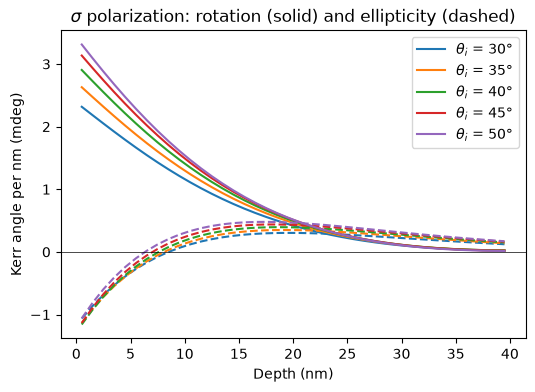

In [7]:
sim = ud.BerremanStepanov(S, True, save_data=False, disp_messages=False, progress_bar=False)
sim.wl = np.r_[400] * u.nm
incidences = np.r_[2.5:87.6:2.5]  # angles of incidence (deg)
sim.theta = (90 - incidences) * u.deg
sim.set_polarization("sigma", "none")

single_layers = np.zeros([N, S.num_layers, 3])
single_layers[np.arange(N), np.arange(N), 1] = 1
res_sensitivity = sim.inhomogeneous_rotation_ellipticity(magnetization_map=single_layers)
rotation = res_sensitivity.quantity("rot_R", "mdeg")
ellipticity = res_sensitivity.quantity("ell_R", "mdeg")
# angles of incidence from the surface normal of the grazing angles theta
incidences = 90 - res_sensitivity.quantity("theta", "deg")[0].magnitude

selected = [30, 35, 40, 45, 50]  # angles of incidence of Fig. 3 of Ashok et al.
plt.figure(figsize=[6, 4])
for incidence in selected:
    j = np.argmin(np.abs(incidences - incidence))
    line = plt.plot(depth, rotation[:, 0, j], label=rf"$\theta_i$ = {incidence}°")
    plt.plot(depth, ellipticity[:, 0, j], "--", color=line[0].get_color())
plt.axhline(0, color="k", lw=0.5)
plt.xlabel("Depth (nm)")
plt.ylabel("Kerr angle per nm (mdeg)")
plt.title(r"$\sigma$ polarization: rotation (solid) and ellipticity (dashed)")
plt.legend()
plt.show()

The sensitivity of the Kerr rotation decreases monotonically with depth.
The sensitivity of the Kerr ellipticity changes its sign within the first nanometers and is largest at about 15 nm to 20 nm, so that the surface and the bottom of the film contribute with opposite signs, whose balance depends on the angle of incidence.
The actual shapes depend on the **estimated** Voigt constant $Q$.

## Transient Kerr Rotation and Ellipticity

The Kerr rotation and ellipticity are calculated for both magnetization maps, all angles of incidence, and the $\sigma$ and $\pi$ polarization.

In [8]:
res_kerrs = {}
kerr = {}
for pol in ["sigma", "pi"]:
    sim.set_polarization(pol, "none")
    for name in m:
        res_kerrs[pol, name] = sim.inhomogeneous_rotation_ellipticity(
            magnetization_map=magnetization_maps[name]
        )
        kerr[pol, name] = (  # delays x angles
            res_kerrs[pol, name].quantity("rot_R")[:, 0, :],
            res_kerrs[pol, name].quantity("ell_R")[:, 0, :],
        )

As in Fig. 3 of {cite:t}`ashok2025`, the Kerr rotation and ellipticity for the $\sigma$ polarization and angles of incidence between 30° and 50° are normalized to their values before the excitation.

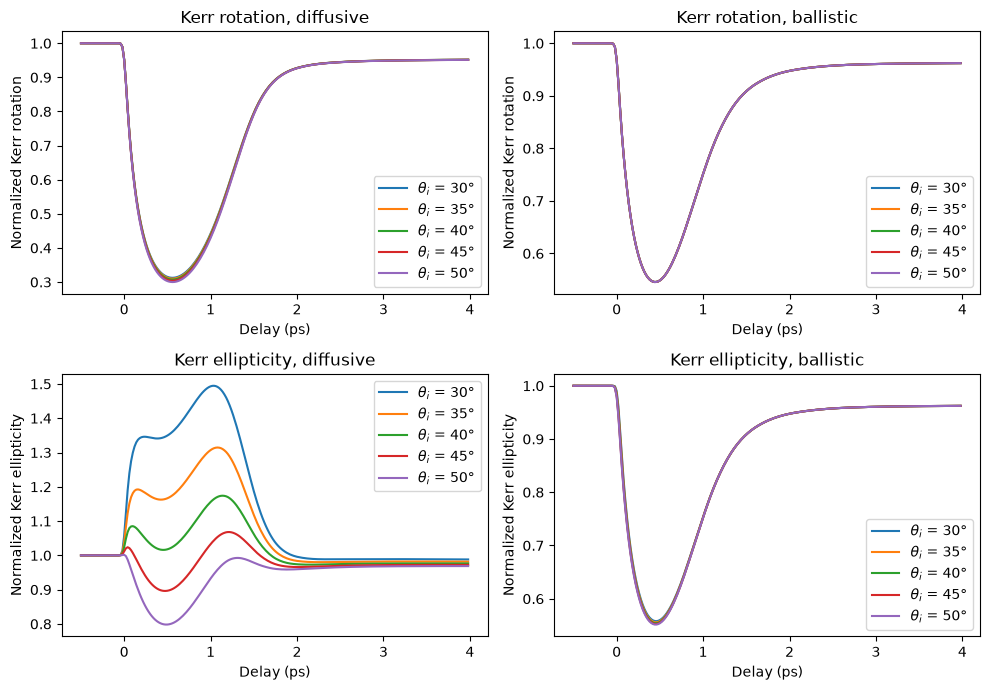

In [9]:
plt.figure(figsize=[10, 7])
for j, name in enumerate(m):
    for i, label in enumerate(["Kerr rotation", "Kerr ellipticity"]):
        plt.subplot(2, 2, 2 * i + j + 1)
        delays_ps = res_temps[name].quantity("delays", "ps")
        for incidence in selected:
            angle = kerr["sigma", name][i][:, np.argmin(np.abs(incidences - incidence))]
            plt.plot(delays_ps, angle / angle[0], label=rf"$\theta_i$ = {incidence}°")
        plt.xlabel("Delay (ps)")
        plt.ylabel(f"Normalized {label}")
        plt.title(f"{label}, {name}")
        plt.legend()
plt.tight_layout()
plt.show()

For ballistic transport, both the Kerr rotation and ellipticity follow the almost homogeneous magnetization and are the same for all angles of incidence.
For diffusive transport, the Kerr rotation follows the strong demagnetization close to the surface for all angles of incidence.
The Kerr ellipticity, however, depends on the angle of incidence and even increases for the smaller angles, as the demagnetization of the surface removes its contribution of the opposite sign.

## Direct Comparison

The normalized Kerr rotation at a large angle of incidence and the normalized Kerr ellipticity at a small angle of incidence are compared directly for the $\sigma$ polarization.

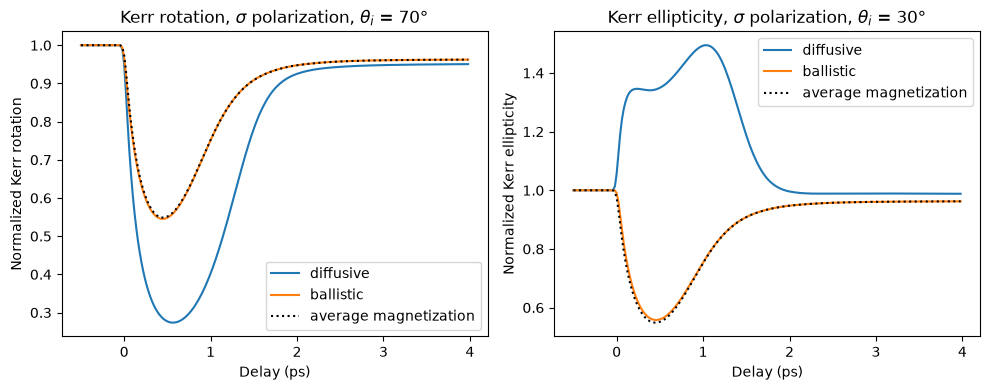

In [10]:
plt.figure(figsize=[10, 4])
for i, (incidence, k, label) in enumerate([(70, 0, "rotation"), (30, 1, "ellipticity")]):
    j = np.argmin(np.abs(incidences - incidence))
    plt.subplot(1, 2, i + 1)
    for name in m:
        angle = kerr["sigma", name][k][:, j]
        plt.plot(res_temps[name].quantity("delays", "ps"), angle / angle[0], label=name)
    plt.plot(
        res_temps["ballistic"].quantity("delays", "ps"),
        m["ballistic"][:, :N].mean(axis=1) / m_eq,
        "k:",
        label="average magnetization",
    )
    plt.xlabel("Delay (ps)")
    plt.ylabel(f"Normalized Kerr {label}")
    plt.title(rf"Kerr {label}, $\sigma$ polarization, $\theta_i$ = {incidence}°")
    plt.legend()
plt.tight_layout()
plt.show()

For ballistic transport, both signals follow the average magnetization.
For diffusive transport, the Kerr rotation overestimates the demagnetization due to its sensitivity to the surface, while the Kerr ellipticity at the small angle of incidence even increases, as the demagnetized surface contributes with the opposite sign.

## Angle and Polarization Dependence

The Kerr rotation $\theta_K$ and ellipticity $\epsilon_K$ are the real and imaginary part of the complex Kerr angle $\Phi_K = \theta_K + i \epsilon_K$.
The difference between diffusive and ballistic transport is shown for all angles of incidence and both polarizations relative to the magnitude of the complex Kerr angle before the excitation

$$|\Phi_K^0| = \sqrt{\theta_K^2 + \epsilon_K^2}\Big|_{t < 0},$$

which is the same for both cases.
In contrast to the normalization by the rotation or ellipticity alone, as above, it does not diverge for angles of incidence, at which one of them vanishes before the excitation, and it allows to compare the rotation and ellipticity on the same scale.

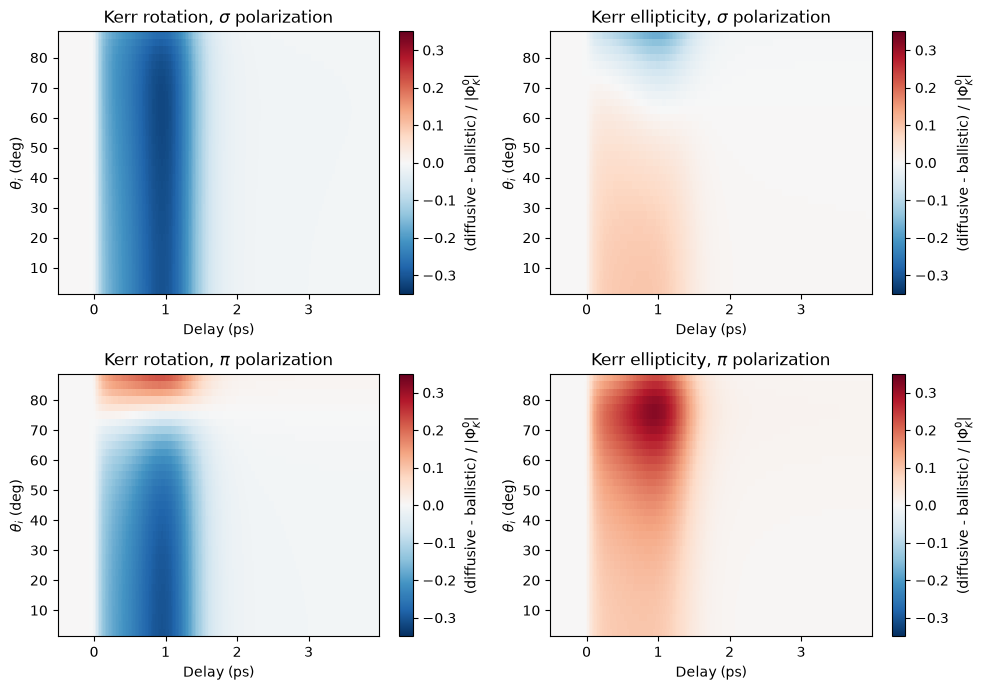

In [11]:
plt.figure(figsize=[10, 7])
for i, pol in enumerate(["sigma", "pi"]):
    rotation_0, ellipticity_0 = (angle[0] for angle in kerr[pol, "ballistic"])
    magnitude_0 = np.sqrt(rotation_0**2 + ellipticity_0**2)
    for j, label in enumerate(["rotation", "ellipticity"]):
        difference = (kerr[pol, "diffusive"][j] - kerr[pol, "ballistic"][j]) / magnitude_0
        plt.subplot(2, 2, 2 * i + j + 1)
        plt.pcolormesh(
            res_temps["ballistic"].quantity("delays", "ps"),
            incidences,
            difference.magnitude.T,
            shading="auto",
            cmap="RdBu_r",
            vmin=-0.35,
            vmax=0.35,
        )
        plt.colorbar(label=r"(diffusive - ballistic) / $|\Phi_K^0|$")
        plt.xlabel("Delay (ps)")
        plt.ylabel(r"$\theta_i$ (deg)")
        plt.title(rf"Kerr {label}, $\{pol}$ polarization")
plt.tight_layout()
plt.show()

The Kerr rotation for the $\sigma$ polarization and the Kerr ellipticity for the $\pi$ polarization at angles of incidence of about 60° to 75° differ most, by about 30 % of the static Kerr angle.
For small angles of incidence, the Kerr ellipticity for the $\sigma$ polarization is small before the excitation, so that its absolute difference is small, but its normalized difference is largest, as its sign is opposite to the one of the Kerr rotation.
Hence, even the complex Kerr effect of visible light at 400 nm for different angles of incidence and polarizations is sensitive to the depth dependence of the magnetization and distinguishes a magnetization gradient from a homogeneous demagnetization.
The depth profile itself can be studied in much more detail by resonant magnetic reflectivity in the XUV and soft X-ray range, which provides element selectivity and a depth resolution on the nanometer scale, see the [example of resonant magnetic X-ray reflectivity](#example_resonant_magnetic_xray).